# Libraries

In [ ]:
!pip install scikeras
!pip install tensorflow

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, roc_curve, auc
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from scikeras.wrappers import KerasClassifier

# Dataset

In [ ]:
dataset = pd.read_csv('/content/drive/MyDrive/CSE422_Project/Bank_Marketing.csv')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

# EDA

Descriptive Analysis

In [ ]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Histograms

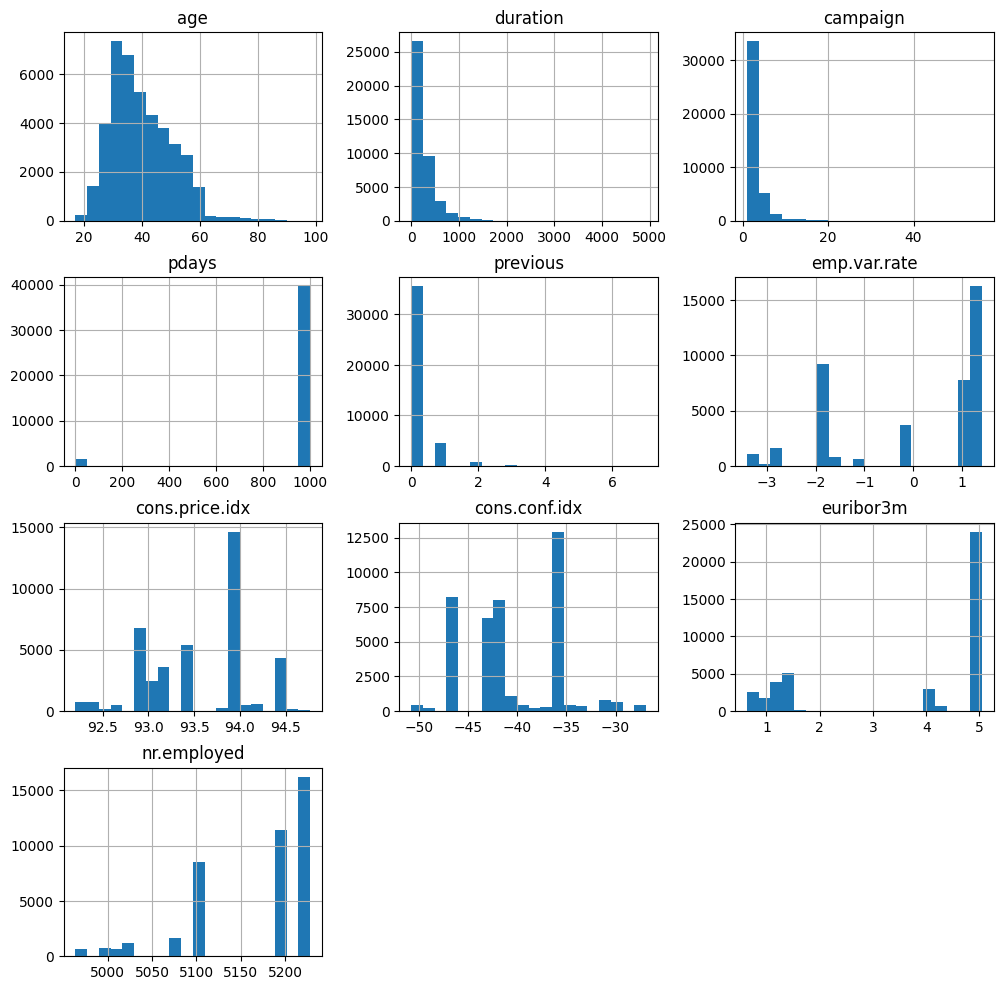

In [ ]:
dataset.hist(figsize=(12,12),bins=20)
plt.show()

Box plots

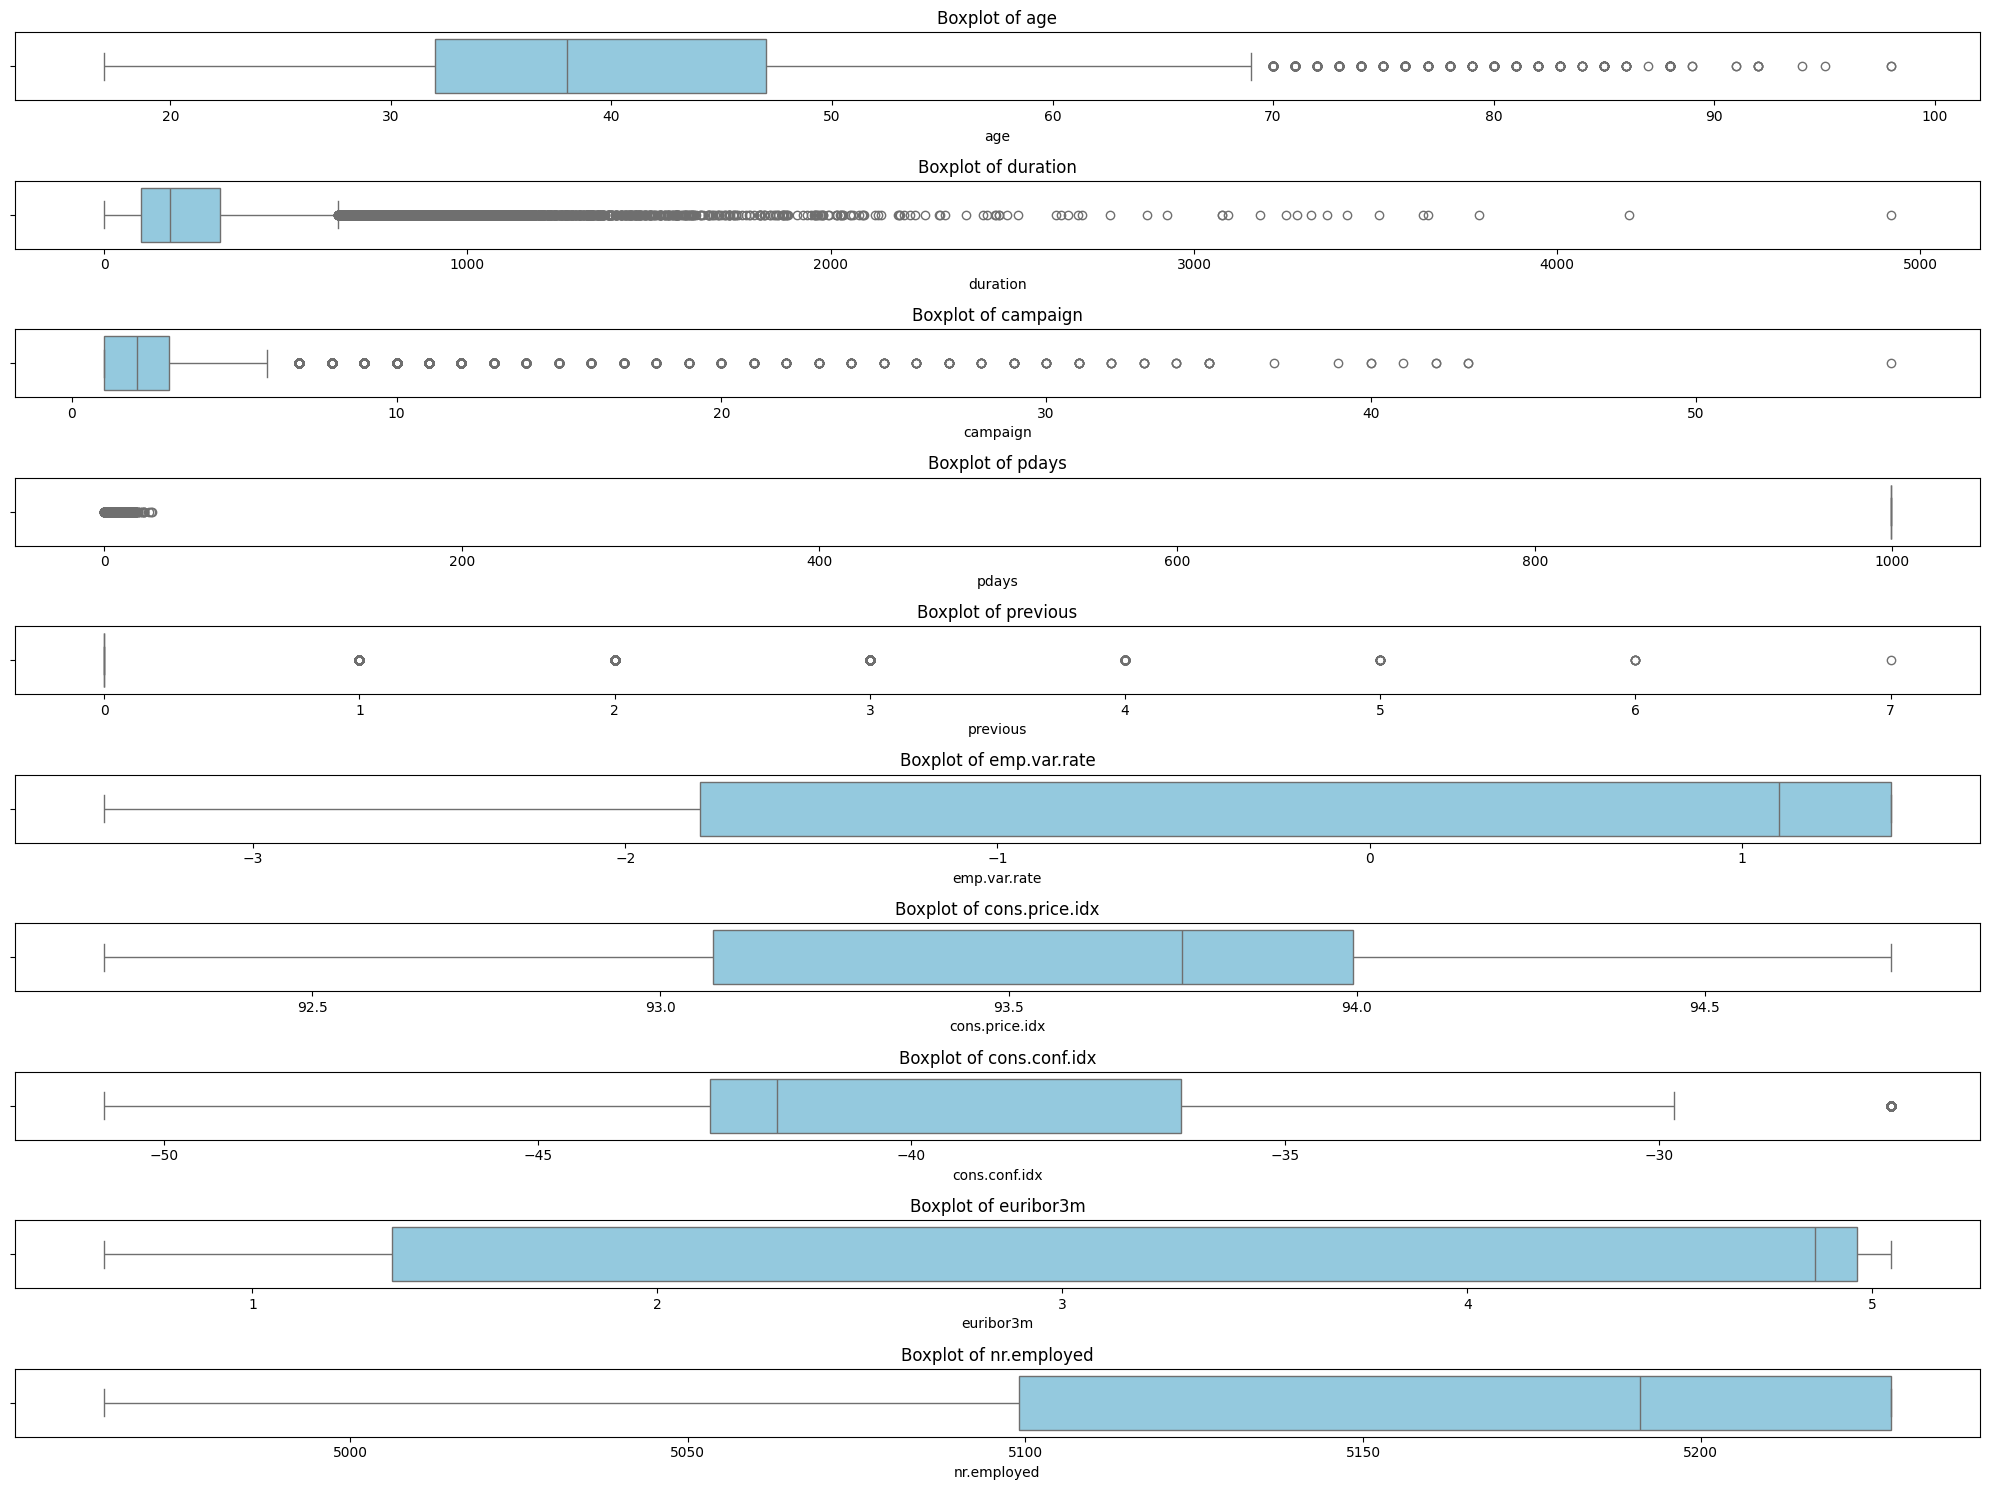

In [ ]:
numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(20, 15))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataset[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()


Number Unique values in each feature

In [ ]:
dataset.nunique()

,0
age,78
job,12
marital,4
education,8
default,3
housing,3
loan,3
contact,2
month,10
day_of_week,5


Null Values

In [ ]:
dataset.isnull().sum()
# No Null Entries

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


No of unique values in each categorical feature

In [ ]:
categorical_data=dataset.select_dtypes(include= 'object')
unique_counts=categorical_data.nunique()
print(unique_counts)

job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
y               2
dtype: int64


Barplot of unique value counts in every categorical features

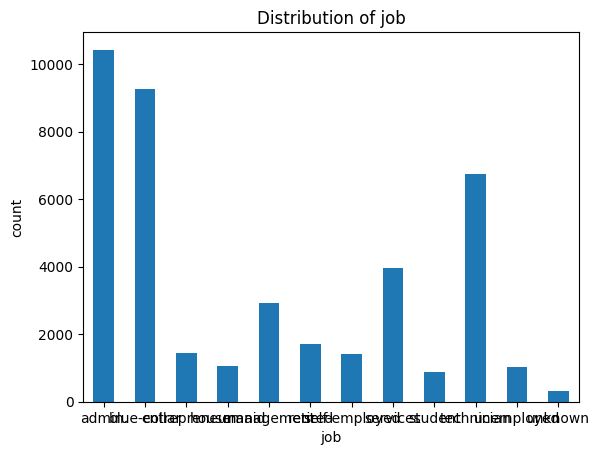

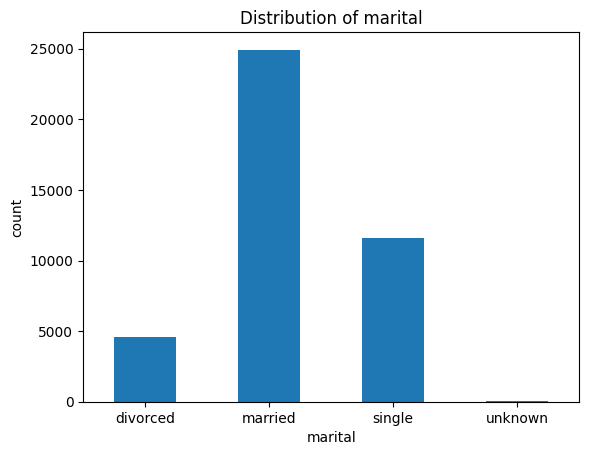

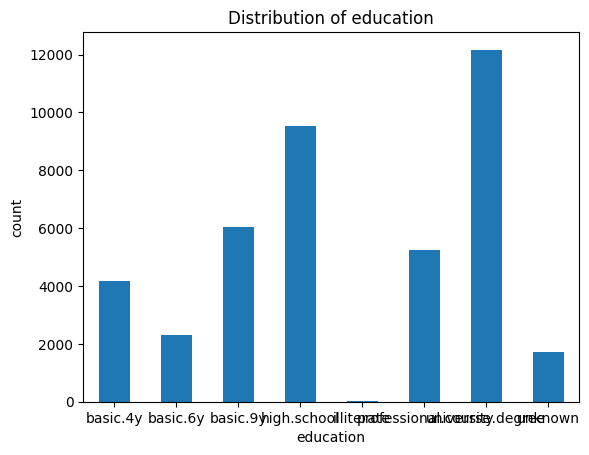

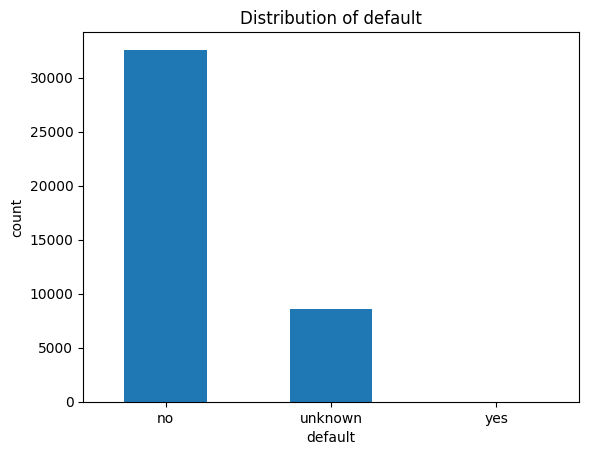

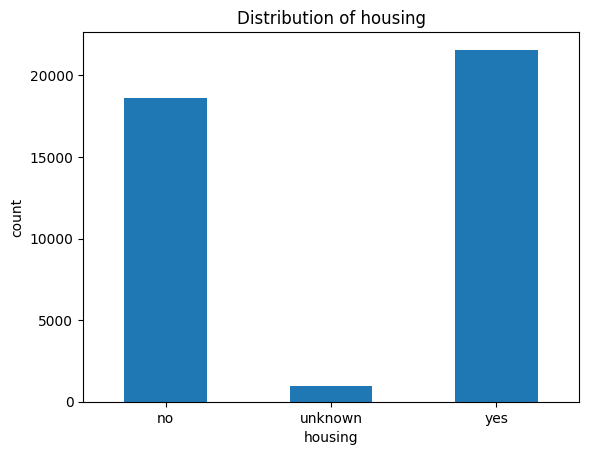

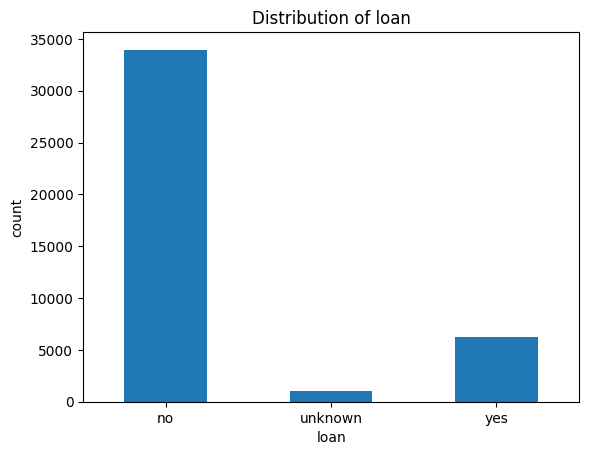

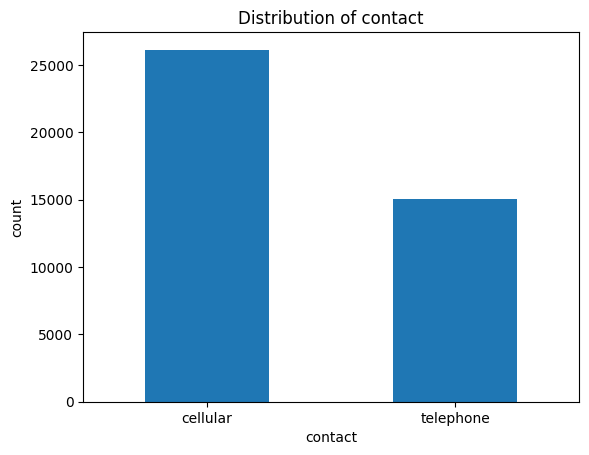

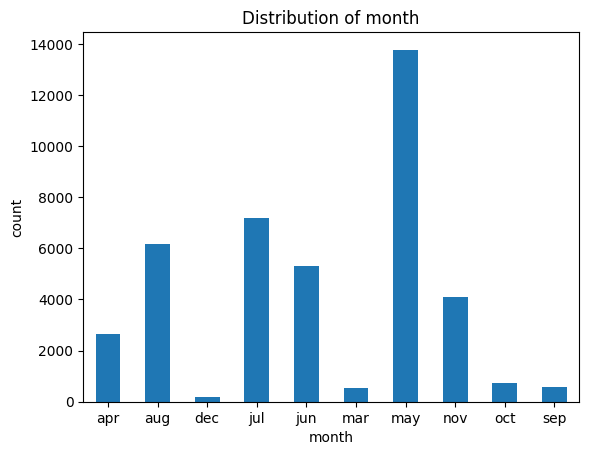

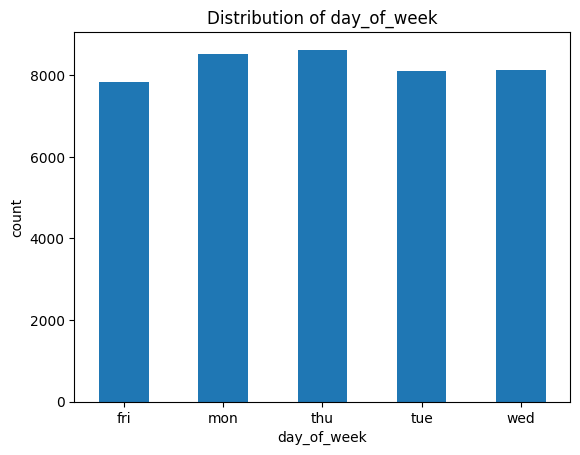

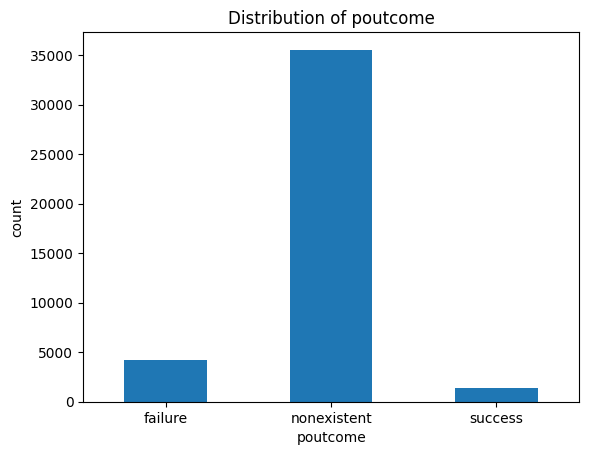

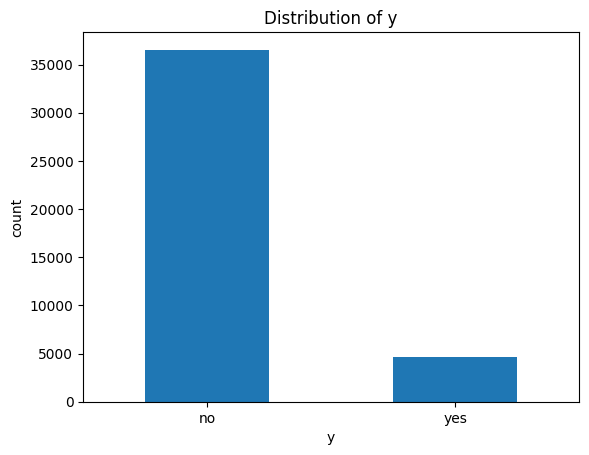

In [ ]:
categorical_features=categorical_data.columns.tolist()
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

Imbalance in Data

In [ ]:
class_counts = dataset.groupby("y").size()

columns = ['outcome', 'count', 'percentage']
outcome=[0,1]
count=list()
percentage=list()

for val in range(2):
    count.append(class_counts.iloc[val])
    percent=(class_counts.iloc[val]/105000)*100
    percentage.append(percent)

imbalance_dataset = pd.DataFrame(list(zip(outcome, count, percentage)), columns=columns)
print(imbalance_dataset)

   outcome  count  percentage
0        0  36548   34.807619
1        1   4640    4.419048


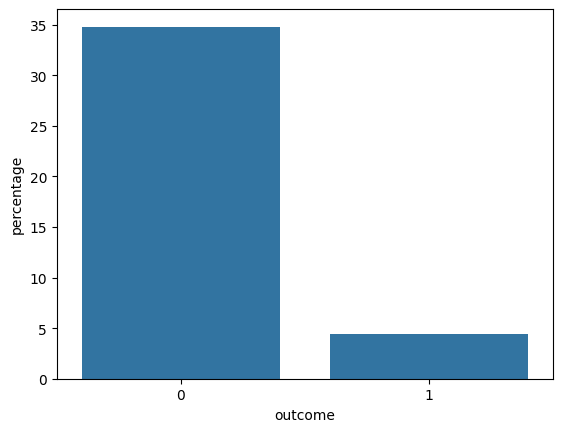

In [ ]:
sns.barplot(data=imbalance_dataset,x=imbalance_dataset['outcome'],y=imbalance_dataset['percentage'])
plt.show()

Initial selection of features

In [ ]:
dataset_copy = dataset.copy()
cat_features = dataset_copy.select_dtypes(include=['object']).columns.tolist()
label_encoder = LabelEncoder()

for feature in cat_features:
    dataset_copy[feature] = label_encoder.fit_transform(dataset_copy[feature])


Correlation Table

In [ ]:
dataset_copy.corr()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,0.001250,-0.389753,-0.117892,0.164965,-0.001603,-0.007368,0.007021,-0.024877,-0.017572,...,0.004594,-0.034369,0.024365,0.019750,-0.000371,0.000857,0.129372,0.010767,-0.017725,0.030399
job,0.001250,1.000000,0.027897,0.134121,-0.028277,0.006962,-0.010209,-0.025132,-0.033213,-0.000844,...,-0.006923,-0.028468,0.020965,0.011504,-0.008271,-0.016017,0.052760,-0.007880,-0.019574,0.025122
marital,-0.389753,0.027897,1.000000,0.109220,-0.079450,0.010467,0.005788,-0.054501,-0.007629,0.002202,...,-0.007240,-0.037942,0.038689,0.001912,-0.084210,-0.057477,-0.033783,-0.091939,-0.086199,0.046203
education,-0.117892,0.134121,0.109220,1.000000,-0.186859,0.016825,0.006384,-0.105726,-0.082684,-0.017986,...,0.000371,-0.046626,0.038831,0.017009,-0.043778,-0.081607,0.078799,-0.036380,-0.041492,0.057799
default,0.164965,-0.028277,-0.079450,-0.186859,1.000000,-0.015815,-0.003782,0.135238,-0.015830,-0.008701,...,0.032825,0.080062,-0.102416,0.023417,0.203263,0.168073,0.026522,0.195336,0.189845,-0.099352
housing,-0.001603,0.006962,0.010467,0.016825,-0.015815,1.000000,0.044296,-0.082186,-0.018141,0.003339,...,-0.011010,-0.010551,0.021314,-0.011783,-0.060196,-0.080504,-0.033845,-0.059277,-0.045862,0.011552
loan,-0.007368,-0.010209,0.005788,0.006384,-0.003782,0.044296,1.000000,-0.008556,-0.005705,-0.009344,...,0.005166,0.000345,-0.001327,-0.001511,0.001849,-0.002430,-0.012025,0.000125,0.003903,-0.004909
contact,0.007021,-0.025132,-0.054501,-0.105726,0.135238,-0.082186,-0.008556,1.000000,0.276565,-0.009575,...,0.077368,0.117970,-0.212848,0.118744,0.393584,0.591474,0.251614,0.399773,0.269155,-0.144773
month,-0.024877,-0.033213,-0.007629,-0.082684,-0.015830,-0.018141,-0.005705,0.276565,1.000000,0.027677,...,-0.062059,-0.047891,0.103157,-0.065012,-0.178782,-0.004239,0.009652,-0.117264,-0.221425,-0.006065
day_of_week,-0.017572,-0.000844,0.002202,-0.017986,-0.008701,0.003339,-0.009344,-0.009575,0.027677,1.000000,...,-0.038288,-0.009531,-0.004102,0.018732,0.033245,0.005644,0.041465,0.039043,0.028380,0.015967


<Axes: >

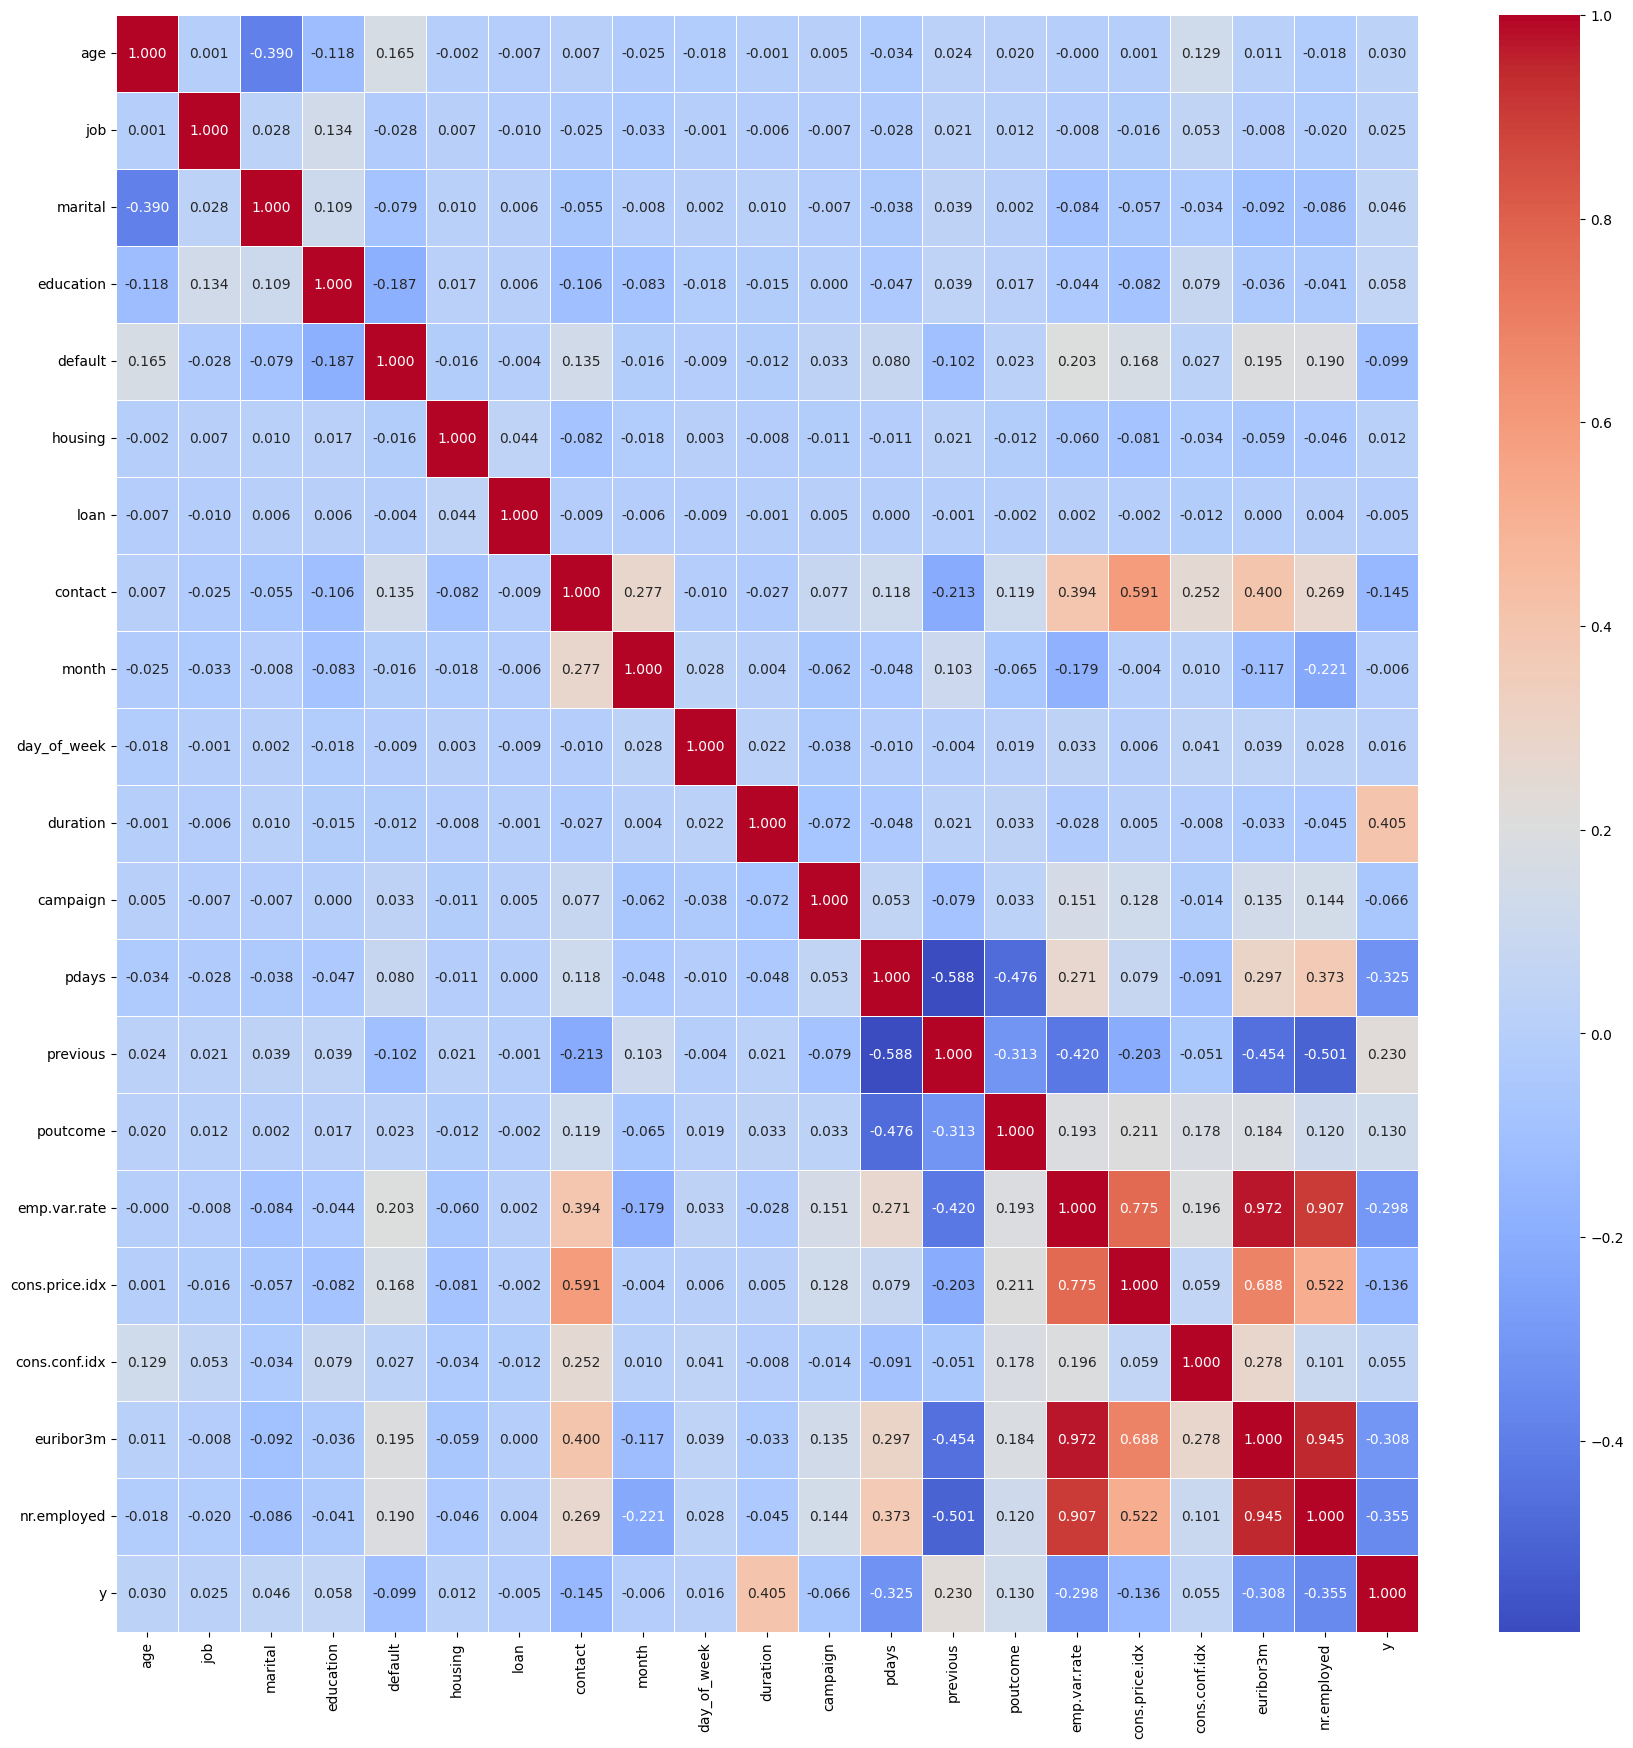

In [ ]:
plt.figure(figsize=(21, 21))
sns.heatmap(dataset_copy.corr(), annot=True, cmap="coolwarm", fmt='.3f', linewidths=0.5)

In [ ]:
dataset_copy.corr()[dataset_copy.columns[-1]].abs().sort_values(ascending=False)

,y
y,1.000000
duration,0.405274
nr.employed,0.354678
pdays,0.324914
euribor3m,0.307771
emp.var.rate,0.298334
previous,0.230181
contact,0.144773
cons.price.idx,0.136211
poutcome,0.129789


# Preprocessing

Dropping Redundant Columns

In [ ]:
dataset = dataset.drop(['emp.var.rate', 'euribor3m', 'nr.employed'], axis = 1)

Handling Categorical Features

In [ ]:
# Handling pdays before encoding
dataset['pdays_contacted'] = (dataset['pdays'] != 999).astype(int)
dataset['pdays_notcontacted'] = dataset['pdays'].replace(999, np.nan)
dataset['pdays_notcontacted'] = np.log1p(dataset['pdays_notcontacted'])
dataset.drop('pdays', axis=1, inplace=True)

In [ ]:
# label encoding y
label_encoder = LabelEncoder()
dataset['y'] = label_encoder.fit_transform(dataset['y'])

# one-hot encoding categorical variables
cat_features = dataset.select_dtypes(include=['object']).columns

cat_features = list(cat_features)

listed = []
for feature in cat_features:
    if feature != 'y':
        listed.append(feature)
cat_features = listed

dataset = pd.get_dummies(dataset, columns=cat_features, drop_first=True)

In [ ]:
# Impuding missing values of pdays_notcontacted
dataset.fillna(dataset.median(numeric_only=True), inplace=True)

Checking Skewness

In [ ]:
dataset.skew()

,0
age,0.784697
duration,3.263141
campaign,4.762507
previous,3.832042
cons.price.idx,-0.230888
cons.conf.idx,0.303180
y,2.450330
pdays_contacted,4.922068
pdays_notcontacted,-3.930468
job_blue-collar,1.319373


Transformation based on skewness (on actual columns - int64/float64)

In [ ]:
numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns

skewness = dataset[numeric_cols].skew()

skewed_cols = skewness[skewness > 1].index.tolist()

for col in skewed_cols:
    if col != 'y' and (dataset[col] >= 0).all():
        dataset[col] = np.log1p(dataset[col])
dataset.skew()

,0
age,0.784697
duration,-0.421327
campaign,1.350403
previous,2.587040
cons.price.idx,-0.230888
cons.conf.idx,0.303180
y,2.450330
pdays_contacted,4.922068
pdays_notcontacted,-3.930468
job_blue-collar,1.319373


# Train-Test

Feature Scaling and Spliting Dataset

In [ ]:
x = dataset.drop('y', axis=1)
y = dataset['y']

# Scale features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(x)

# spliting
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size = 0.30, stratify=y, random_state=42)

Checking Train-Test Size

In [ ]:
print(f"X_train Shape: {X_train.shape}")
print(f"y_train Shape: {y_train.shape}")

print(f"X_test Shape: {X_test.shape}")
print(f"y_test Shape: {y_test.shape}")

X_train Shape: (28831, 51)
y_train Shape: (28831,)
X_test Shape: (12357, 51)
y_test Shape: (12357,)


Check Label Frequency

Text(0, 0.5, 'y')

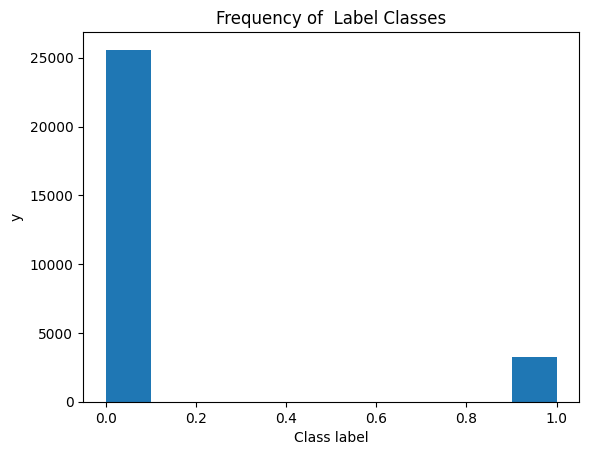

In [ ]:
fig, ax = plt.subplots()
ax.hist(y_train)
ax.set_title('Frequency of  Label Classes')
ax.set_xlabel('Class label')
ax.set_ylabel('y')

# SMOTE

In [ ]:
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Models

In [ ]:
def nn():
    model =  Sequential([
        Dense(64, input_shape=(X_train.shape[1],), activation='relu'),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
        ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, class_weight='balanced'),
    'KNN': KNeighborsClassifier(n_neighbors = 4),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced'),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'Naive Bayes': GaussianNB(),
    'SVM': SVC(probability=True, class_weight='balanced'),
    'Neural Network': KerasClassifier(build_fn=nn, epochs=40, batch_size=20, verbose=0)
    }

#ROC and AUC

/usr/local/lib/python3.11/dist-packages/scikeras/wrappers.py:925: UserWarning: ``build_fn`` will be renamed to ``model`` in a future release, at which point use of ``build_fn`` will raise an Error instead.
  X, y = self._initialize(X, y)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


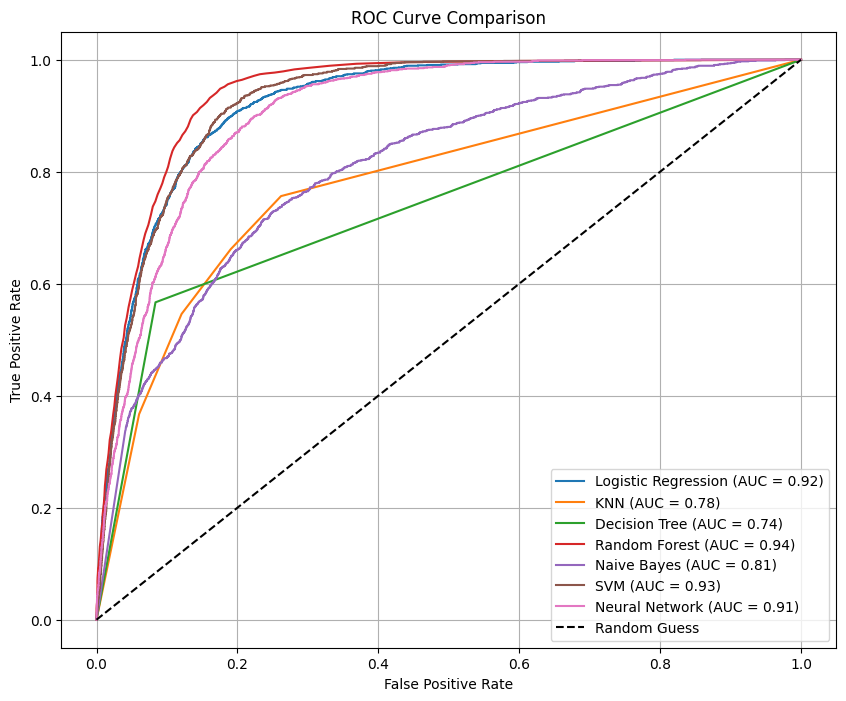

In [ ]:
predictions = {}
probabilities = {}

plt.figure(figsize=(10, 8))

for name, model in models.items():
    # train models
    model.fit(X_train, y_train)

    y_pred = ""
    y_probs = ""

    if name == "Neural Network":
        y_pred = model.predict(X_test)
        y_pred = (y_pred >= 0.5).astype(int).flatten()
    else:
        y_pred = model.predict(X_test)

    # Predict probabilities
    y_probs = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_probs

    # ROC and AUC
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = auc(fpr, tpr)

    # Plot
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot random line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Final plot setup
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid()
plt.show()

Confusion Matrices

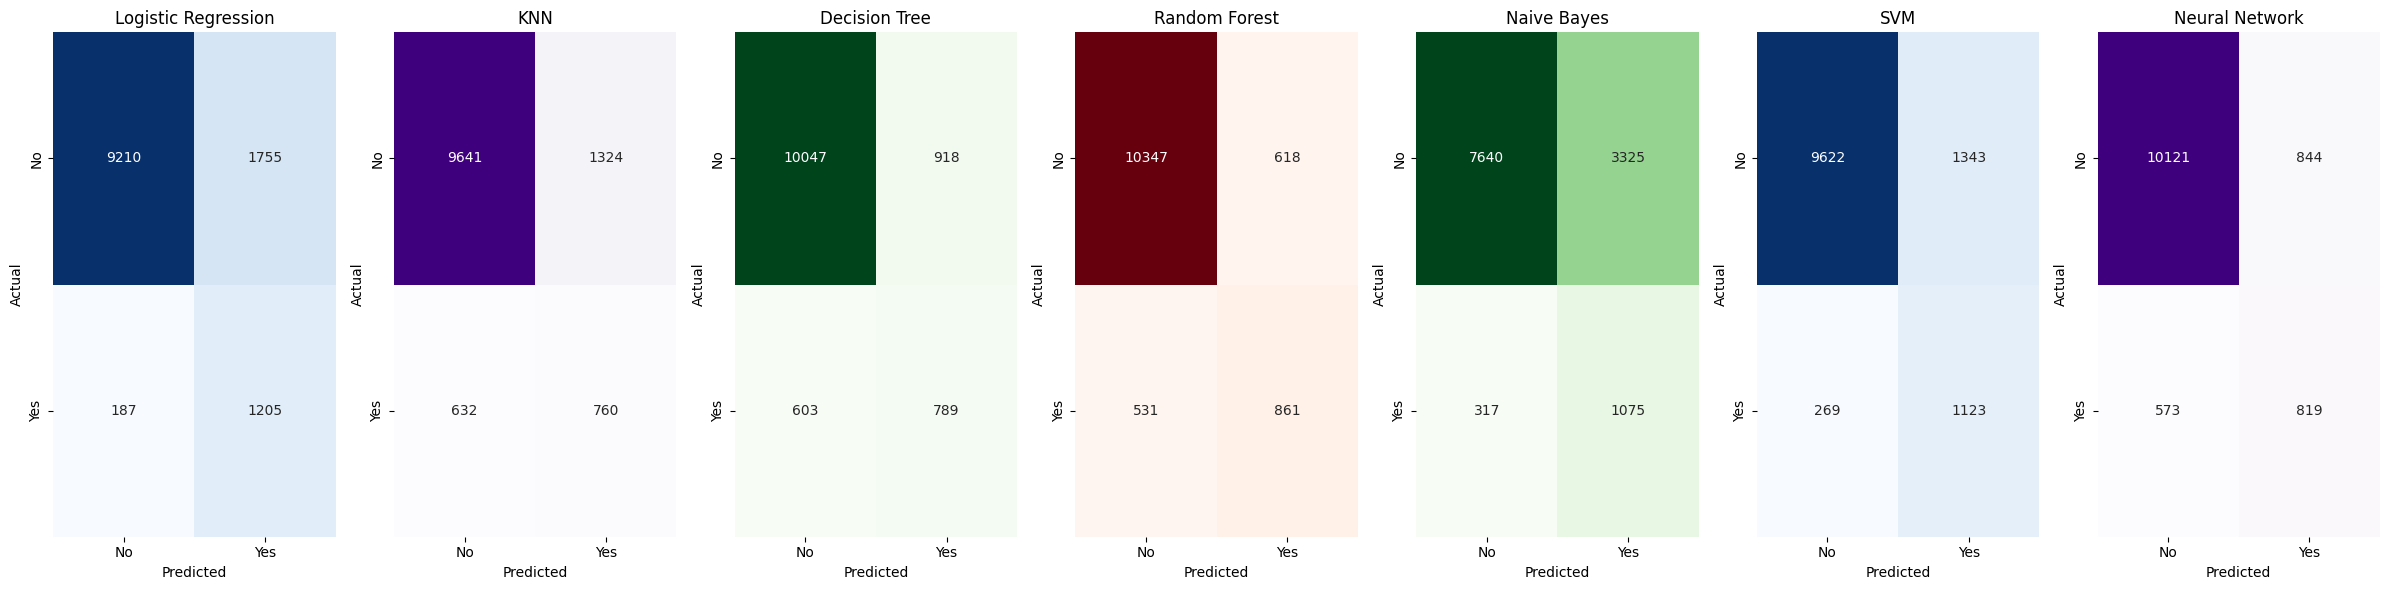

In [ ]:
fig, axes = plt.subplots(1, 7, figsize=(24, 6))

model_cmaps = {
    "Logistic Regression": "Blues",
    "KNN": "Purples",
    "Decision Tree": "Greens",
    "Random Forest": "Reds",
    "Naive Bayes": "Greens",
    "SVM": "Blues",
    "Neural Network": "Purples"
}

i = 0
for name in model_cmaps:
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d',  cmap=model_cmaps[name], ax=axes[i], cbar=False,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")
    i += 1

plt.tight_layout()
plt.show()


#Classification Reports

In [ ]:
reports = {}
for name in models.keys():
    y_pred = predictions[name]

    report = classification_report(y_test, y_pred, target_names=["No", "Yes"], output_dict=True)
    reports[name] = report

    # Format and print as DataFrame
    print(f"\n{name} Classification Report:\n")
    pd.options.display.float_format = '{:.2f}'.format
    print(pd.DataFrame(report).T)


Logistic Regression Classification Report:

              precision  recall  f1-score  support
No                 0.98    0.84      0.90 10965.00
Yes                0.41    0.87      0.55  1392.00
accuracy           0.84    0.84      0.84     0.84
macro avg          0.69    0.85      0.73 12357.00
weighted avg       0.92    0.84      0.87 12357.00

KNN Classification Report:

              precision  recall  f1-score  support
No                 0.94    0.88      0.91 10965.00
Yes                0.36    0.55      0.44  1392.00
accuracy           0.84    0.84      0.84     0.84
macro avg          0.65    0.71      0.67 12357.00
weighted avg       0.87    0.84      0.85 12357.00

Decision Tree Classification Report:

              precision  recall  f1-score  support
No                 0.94    0.92      0.93 10965.00
Yes                0.46    0.57      0.51  1392.00
accuracy           0.88    0.88      0.88     0.88
macro avg          0.70    0.74      0.72 12357.00
weighted avg       0

Neural Network Loss Curve

Epoch 1/40


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2047/2047 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8258 - loss: 0.3815 - val_accuracy: 0.8898 - val_loss: 0.3518
Epoch 2/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8879 - loss: 0.2675 - val_accuracy: 0.9227 - val_loss: 0.2825
Epoch 3/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8982 - loss: 0.2471 - val_accuracy: 0.9420 - val_loss: 0.2269
Epoch 4/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9069 - loss: 0.2335 - val_accuracy: 0.9145 - val_loss: 0.2896
Epoch 5/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9127 - loss: 0.2187 - val_accuracy: 0.9516 - val_loss: 0.2052
Epoch 6/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9193 - loss: 0.2050 - val_accuracy: 0.9509 - val_loss: 0.2019
Epoch 7/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9227 - loss: 0.1944 - val_accuracy: 0.9564 - val_loss: 0.1907
Epoch 8/40
2047/2047 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9246 - loss: 0.1928 - val_accur

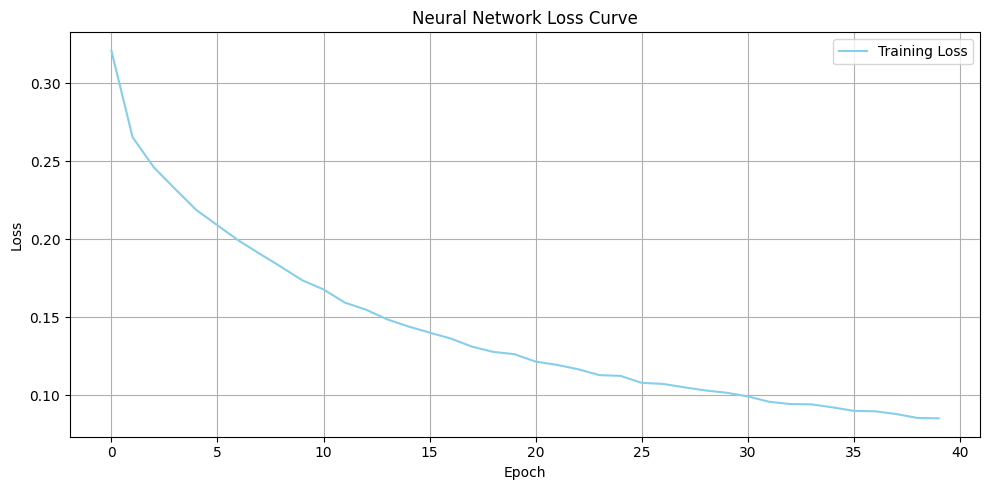

In [ ]:
loss_model = nn()

history = loss_model.fit(X_train, y_train, validation_split=0.2,epochs=40, batch_size=20, verbose=1)

if history:
    plt.figure(figsize=(10, 5))
    plt.plot(history.history['loss'], label='Training Loss', color='skyblue')
    plt.title('Neural Network Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

#Plot comparison of models

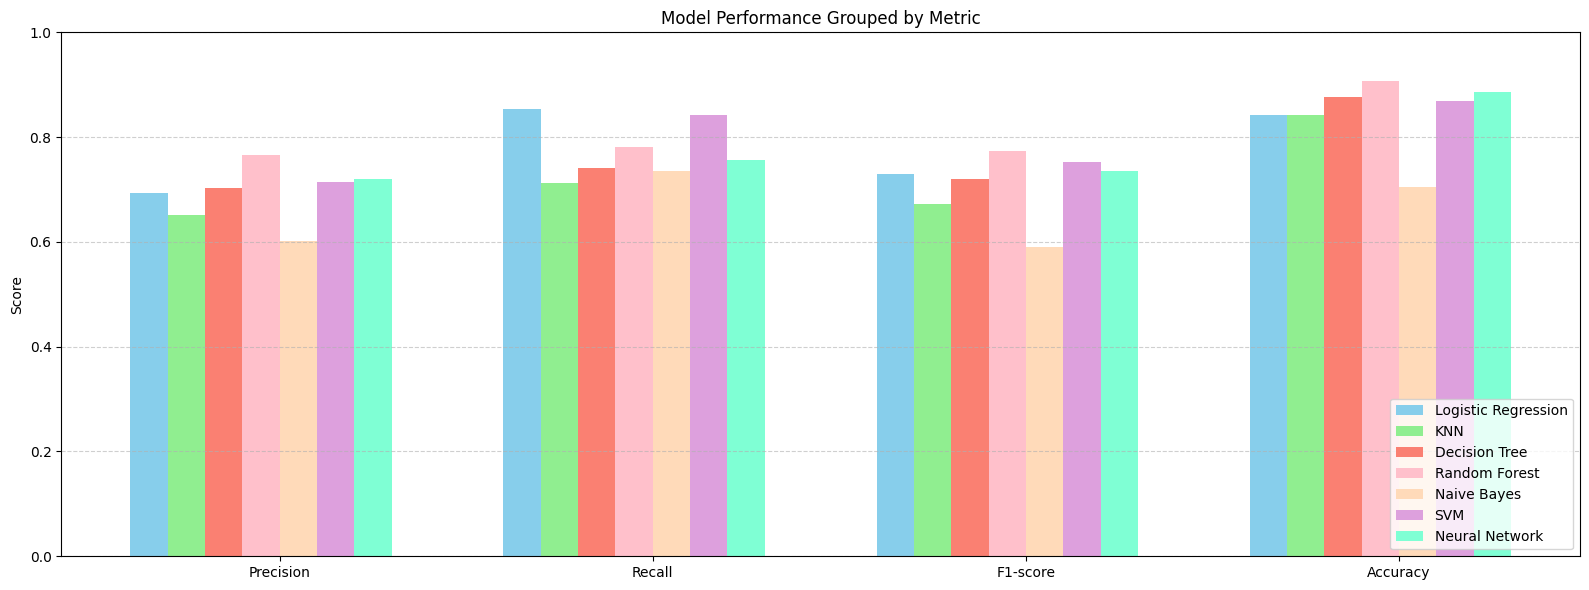

In [ ]:
metrics = ['Precision', 'Recall', 'F1-score', 'Accuracy']
models = list(reports.keys())

precision = [reports[m]['macro avg']['precision'] for m in models]
recall = [reports[m]['macro avg']['recall'] for m in models]
f1 = [reports[m]['macro avg']['f1-score'] for m in models]
accuracy = [reports[m]['accuracy'] for m in models]

data = [precision, recall, f1, accuracy]

# Plot
x = np.arange(len(metrics))
width = 0.1
plt.figure(figsize=(16, 6))

colors = ['skyBlue', 'lightGreen', 'salmon', 'pink', 'PeachPuff', 'Plum', 'Aquamarine']

for i, model in enumerate(models):
    plt.bar(x + (i - len(models)/2)*width,
            [data[j][i] for j in range(len(metrics))],
            width, label=model, color=colors[i % len(colors)])

# Labels and legend
plt.xticks(x, metrics)
plt.ylabel('Score')
plt.ylim(0, 1)
plt.title('Model Performance Grouped by Metric')
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


#Final Verdict

| Model                          | Precision | Recall | F1-Score | Accuracy |
| ------------------------------ | --------- | ------ | -------- | -------- |
| Logistic Regression            | 0.41      | **0.87**   | 0.55     | 0.84     |
| K-Nearest Neighbors (KNN)      | 0.36      | 0.55   | 0.44     | 0.84     |
| Decision Tree                  | 0.46      | 0.57   | 0.51     | 0.88     |
| Random Forest                  | **0.58**      | 0.62   | **0.60**     | **0.91**     |
| Naive Bayes                    | 0.24      | 0.77   | 0.37     | 0.71     |
| Support Vector Machine (SVM)   | 0.46      | 0.81   | 0.58     | 0.87     |
| Neural Network                 | 0.49      | 0.59   | 0.54     | 0.87     |


| Aspect                | Best Model           | Remarks                                                          |
| --------------------- | -------------------- | ---------------------------------------------------------------- |
| Accuracy              | Random Forest        | Highest overall accuracy (0.91), strong on majority‐class performance |
| Precision (Yes)       | Random Forest        | Best precision (0.60) for predicting “Yes,” fewer false positives |
| Recall (Yes)          | Logistic Regression  | Best at identifying actual “Yes” cases (Recall = 0.87)           |
| F1-Score (Yes)        | Random Forest        | Best trade-off between precision and recall (F1 = 0.60)          |

**Overall best model depends on priority:**  
- **For Maximize recall** Use **Logistic Regression** (Recall = 0.87) to catch the most positives.  
- **For Maximize balance (F1)** Use **Random Forest** (F1 = 0.60) for the best harmonic mean of precision & recall.  
